# [drosophila_body_orientation_predictor](https://github.com/nehalsinghmangat/drosophila_body_orientation_predictor) — Data Correction and Processing

This notebook cleans, corrects, and augments the experimental data from [van Breugel et al. (2014)](https://www.sciencedirect.com/science/article/pii/S0960982213015820) to produce the dataset used to train the heading predictor neural network.


## Data Correction and Processing

The augmentation and correction pipeline goes through the following steps:

- 1. **`01_merged/`** — Raw parquet files of body orientation and trajectory data are merged across wind speeds (30/40/60 cm/s) to create one all_wind_heading_and_trajectories.csv file
- 2. **`02_augmented/`** — Kinematic features (groundspeed, airspeed, thrust) are computed: all_wind_heading_and_trajectories.csv -> all_wind_heading_and_trajectories_augmented.csv
- 3. **`03_corrected/`** — 180° heading ambiguities in the data are corrected: all_wind_heading_and_trajectories_augmented.csv -> all_wind_heading_and_trajectories_augmented_corrected.csv
- 4. **`04_trainingdata/`** — Output columns (`heading_angle_x`, `heading_angle_y`) computed: all_wind_heading_and_trajectories_augmented_corrected.csv -> all_wind_heading_and_trajectories_augmented_corrected_headx_heady.csv

We save intermediate outputs under  `../trainingdata/` for the sake of sanity-checking and to let us load data from the previous step without having to rerun the cell. 

### `01_merged/`

We use data from [van Breugel et al. (2014)](https://doi.org/10.1242/jeb.098665), collected across three constant-wind conditions (30, 40, 60 cm/s). Two data streams are merged per trajectory: (i) flight trajectory (x/y position and velocity) and (ii) body-orientation measurements (captured as ellipse parameters). Trajectories shorter than a minimum duration are discarded to ensure adequate temporal context for model training.

Below, we load the raw Parquet files for each wind speed, correct the airspeed reference frame, standardize field names, and merge the two streams into a single CSV: each trajectory frame is paired with the body-orientation frame nearest to it in time (raw timestamps, within half a frame).

In [1]:
import os
import sys
import pandas as pd
import datetime

sys.path.insert(0, os.path.abspath('../utils'))

from utils import (
    correct_for_wind,
    remove_irrelevant_trajectory_data,
    remove_irrelevant_body_data,
    join_all_body_and_trajec_df,
    transform_timestamps_to_start_at_zero,
)

/Users/florisvb/src/drosophila_body_orientation_predictor/.venv/lib/python3.12/site-packages/pynumdiff/__init__.py:9: UserWarning: tvrdiff, robustdiff, and lineardiff not available due to lack of convex solver. To use those, install CVXPY.
  warn("tvrdiff, robustdiff, and lineardiff not available due to lack of convex solver. To use those, install CVXPY.")


In [2]:

windspeeds = ["30cms", "40cms", "60cms"]
for windspeed in windspeeds:
    trajec_df = pd.read_parquet(f"../experimentaldata/{windspeed}/flight_trajectories_3d_HCS_odor_horizon_matched.parquet")
    body_df = pd.read_parquet(f"../experimentaldata/{windspeed}/body_orientations_HCS_odor_horizon_matched.parquet")
    key_table = pd.read_parquet(f"../experimentaldata/{windspeed}/body_trajec_matches.parquet")

    trajec_df = correct_for_wind(trajec_df)
    trajec_df = remove_irrelevant_trajectory_data(trajec_df)
    body_df = remove_irrelevant_body_data(body_df)

    body_and_trajectory = join_all_body_and_trajec_df(body_df, trajec_df, key_table)
    body_and_trajectory = [transform_timestamps_to_start_at_zero(t) for t in body_and_trajectory]
    body_and_trajectory = [t for t in body_and_trajectory if len(t) > 12] # get rid of trajec that are too short

    temp_fly_data = pd.concat(body_and_trajectory, ignore_index=True)
    os.makedirs(f"../trainingdata/01_merged/{windspeed}", exist_ok=True)
    temp_fly_data.to_csv(f"../trainingdata/01_merged/{windspeed}/fly_trajectories_with_body_orientations.csv", index=False)

temp_file_paths = [
    "../trainingdata/01_merged/30cms/fly_trajectories_with_body_orientations.csv",
    "../trainingdata/01_merged/40cms/fly_trajectories_with_body_orientations.csv",
    "../trainingdata/01_merged/60cms/fly_trajectories_with_body_orientations.csv",
]
temp_dfs = [pd.read_csv(f) for f in temp_file_paths]
heading_and_trajectories = pd.concat(temp_dfs, ignore_index=True)
heading_and_trajectories.to_csv('../trainingdata/01_merged/all_wind_heading_and_trajectories.csv', index=False)

### Post `01_merged/`
Pull in data if you've already run the cell above. 

In [3]:
import os
import sys
import pandas as pd
import datetime

sys.path.insert(0, os.path.abspath('../utils'))

import pynumdiff as pynd
import numpy as np

from utils import augment_fly_trajectory

all_fly_data = pd.read_csv('../trainingdata/01_merged/all_wind_heading_and_trajectories.csv')
all_fly_data.head()

,trajec_objid,timestamp,position_x,position_y,velocity_x,velocity_y,airvelocity_x,airvelocity_y,windspeed,windspeed_angle,eccentricity,ellipse_short_angle
0,20130327_193200_17336,0.00,0.198190,0.005724,0.349395,0.092625,0.049395,0.092625,0.3,-3.141593,0.316778,-0.553696
1,20130327_193200_17336,0.01,0.201661,0.006627,0.344783,0.087979,0.044783,0.087979,0.3,-3.141593,0.421360,-0.711357
2,20130327_193200_17336,0.02,0.205085,0.007483,0.340014,0.083228,0.040014,0.083228,0.3,-3.141593,0.378154,-1.066600
3,20130327_193200_17336,0.03,0.208461,0.008291,0.335091,0.078371,0.035091,0.078371,0.3,-3.141593,0.316603,-1.264121
4,20130327_193200_17336,0.04,0.211787,0.009050,0.330013,0.073410,0.030013,0.073410,0.3,-3.141593,0.355797,-1.330672


### `02_augmented/`

We augment each merged trajectory with derived quantities: groundspeed, airspeed, thrust, and heading angle.The heading angle is derived from the ellipse short-axis angle (accurate only modulo π — corrected via thrust angle in next step).

In [4]:
body_and_trajectory_by_id = [group for _, group in all_fly_data.groupby('trajec_objid')] # seperate data by id for augmentation
temp_augmented_all_fly_data = [augment_fly_trajectory(df, compute_heading_from_ellipses=True) for df in body_and_trajectory_by_id]
augmented_all_fly_data = pd.concat(temp_augmented_all_fly_data, ignore_index=True)
os.makedirs('../trainingdata/02_augmented', exist_ok=True)
augmented_all_fly_data.to_csv('../trainingdata/02_augmented/all_wind_heading_and_trajectories_augmented.csv', index=False)

### Post `02_augmented/
Pull in data if you've already run the cell above.

In [5]:
import os
import sys
import pandas as pd
import datetime
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
sys.path.insert(0, os.path.abspath('../utils'))
augmented_all_fly_data = pd.read_csv('../trainingdata/02_augmented/all_wind_heading_and_trajectories_augmented.csv')
heading_and_trajectory_by_id = [group for _, group in augmented_all_fly_data.groupby('trajec_objid')]

### `03_corrected/`
The body-orientation measurements were captured with a top-down camera where the fly was approximated as an ellipse. Therefore, the recorded heading is only accurate modulo π (the ellipse gives the body axis but not which end is the head). This created discontinuous π-jumps throughout many trajectories.

`heading_correction_viterbi` resolves the ambiguity as follows:

- 1. The body axis is made continuous with `np.unwrap` (period π).
- 2. A single-frame outlier that deviates sharply from its neighbors while said neighbors are close to each other is indicative of a bad measurement. Concretely, a frame is flagged if it deviates by more than 40° from both of its neighbors while those neighbors are within 30° of each other, and its axis is linearly interpolated.
- 3. Each frame then has two candidate headings, the axis and the axis + 180°. The front/back choice of every frame is made jointly, by a two-state Viterbi pass that maximizes the per-frame evidence plus the continuity between consecutive frames:
  - **Evidence**: agreement with the thrust direction, weighted by thrust magnitude (no weight below ~3 µN, where the thrust direction is nearly unrelated to the body axis; full weight above ~8 µN), plus a weaker (0.3×) agreement with the airspeed direction, weighted by airspeed (0.3 → 0.7 m/s).
  - **Continuity**: consecutive frames keep the same front/back choice unless the evidence outweighs it. Continuity is strong when both body ellipses are elongated and weak when either is nearly round (eccentricity 0.6 → 0.9), where the measured axis is unreliable, so the parts of a trajectory on either side of such frames are decided by their own evidence.
- 4. `heading_confidence` is the posterior probability (forward-backward) of the chosen front/back assignment (usually 0.5–1).

The weights and thresholds come from how closely each cue follows the measured body axis, and were checked against hand labels of 285 trajectories (`heading_labeling/`): the defaults were not improved by tuning, and the confidence tracks disagreement with the hand labels.

In [6]:
import os
from utils import heading_correction_viterbi

augmented_all_fly_data = pd.read_csv('../trainingdata/02_augmented/all_wind_heading_and_trajectories_augmented.csv')
body_and_trajectory_by_id = [group for _, group in augmented_all_fly_data.groupby('trajec_objid')]
temp_dfs = []
for traj in body_and_trajectory_by_id:
    corrected_trajec = heading_correction_viterbi(traj.copy())
    temp_dfs.append(corrected_trajec)
corrected_aug_all_fly_data = pd.concat(temp_dfs, ignore_index=True)
os.makedirs('../trainingdata/03_corrected', exist_ok=True)
corrected_aug_all_fly_data.to_csv('../trainingdata/03_corrected/all_wind_heading_and_trajectories_augmented_corrected.csv', index=False)

### Post `03_corrected/
Pull in data if you've already run the cell above.

In [7]:
import os, sys
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('../utils'))
import pandas as pd

augmented_all_fly_data = pd.read_csv('../trainingdata/02_augmented/all_wind_heading_and_trajectories_augmented.csv')
corrected_fly_data  = pd.read_csv('../trainingdata/03_corrected/all_wind_heading_and_trajectories_augmented_corrected.csv')    

##### Visualize Heading Correction
This lets us visualize the before-and-after of the heading correction. 

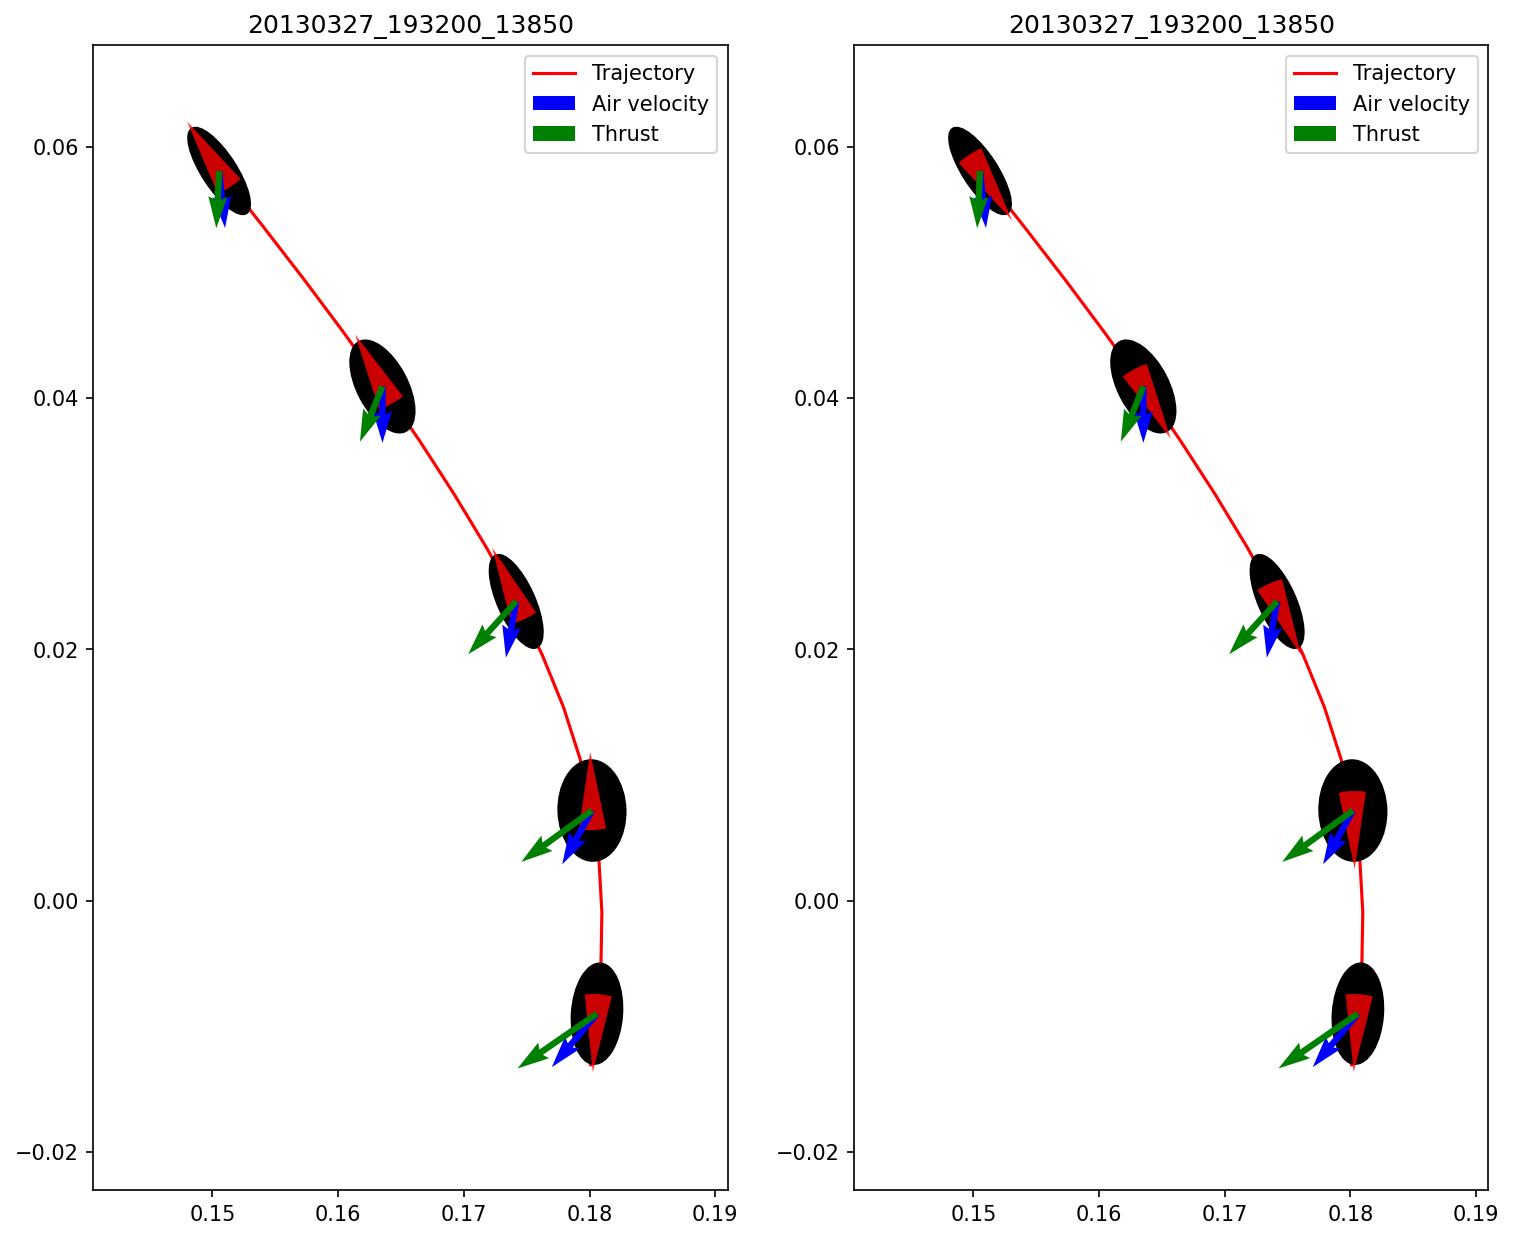

In [8]:
from utils import plot_trajectory
TRAJEC_ID = "20130327_193200_13850"
test_trajec = augmented_all_fly_data.loc[augmented_all_fly_data["trajec_objid"] == TRAJEC_ID]
corr_trajec = corrected_fly_data.loc[corrected_fly_data["trajec_objid"] == TRAJEC_ID]

fig, axs = plt.subplots(1, 2, figsize=(12, 12), dpi=150)
plot_trajectory(axs[0], test_trajec, heading_color='red', heading_size=0.3,arrow_width=0.010,arrow_scale=0.7)
plot_trajectory(axs[1], corr_trajec, heading_color='red', heading_size=0.3,arrow_width=0.010,arrow_scale=0.7)

os.makedirs('../figures', exist_ok=True)
fig.savefig(f'../figures/heading_correction_{TRAJEC_ID}.svg', format='svg', bbox_inches='tight')
plt.show()

##### Visualizing Correction on All Trajectories

Generates before-and-after plots of all trajectories like in the cell above. This is optional and slow (thousands of plots), so it only runs with `PLOT_ALL_TRAJECTORIES = True`.

In [9]:
import gc
import numpy as np
from utils import plot_trajectory

PLOT_ALL_TRAJECTORIES = False   # True: write one before/after SVG per trajectory (slow)


def scaled_style(traj, n_arrows=28):
    """plot_trajectory keyword arguments that scale the glyphs (ellipses, heading triangles, air-velocity
    and thrust arrows) to the trajectory's spatial extent and thin the frames to about `n_arrows`,
    so short and long trajectories are equally legible. Use the same style on a before/after pair."""
    x, y = traj['position_x'].values, traj['position_y'].values
    extent = max(np.ptp(x), np.ptp(y), 1e-3)
    xymean = max(np.mean(np.abs(np.hstack((x, y)))), 1e-6)
    return dict(every_nth=max(2, len(traj) // n_arrows), L=0.04 * extent,
                heading_color='red', heading_size=0.09 * extent / (0.21 * xymean),
                arrow_scale=6 * extent, arrow_width=0.006)


if PLOT_ALL_TRAJECTORIES:
    # Before = measured heading (02_augmented); after = corrected heading (04_trainingdata)
    raw_all = pd.read_csv('../trainingdata/02_augmented/all_wind_heading_and_trajectories_augmented.csv')
    raw_by_id = {tid: g for tid, g in raw_all.groupby('trajec_objid')}
    body_and_trajectory_by_id = [group for _, group in corrected_fly_data.groupby('trajec_objid')]
    print(f"Visualizing {len(body_and_trajectory_by_id)} trajectories...")

    os.makedirs('../trainingdata/corrected_trajectory_plots', exist_ok=True)
    for trajectory in body_and_trajectory_by_id:
        trajec_objid = trajectory["trajec_objid"].iloc[0]
        fig, axs = plt.subplots(1, 2, figsize=(12, 12), dpi=150)

        style = scaled_style(raw_by_id[trajec_objid])   # same style on both panels
        plot_trajectory(axs[0], raw_by_id[trajec_objid], **style)
        plot_trajectory(axs[1], trajectory, **style)

        svg_filename = f'../trainingdata/corrected_trajectory_plots/{trajec_objid}.svg'
        plt.savefig(svg_filename, format='svg')
        plt.close(fig)
        gc.collect()

    print("Done.")

##### Visualize Kinematic Variables over Trajectory
This lets us visualize kinematic variables of interest over a trajectory. 

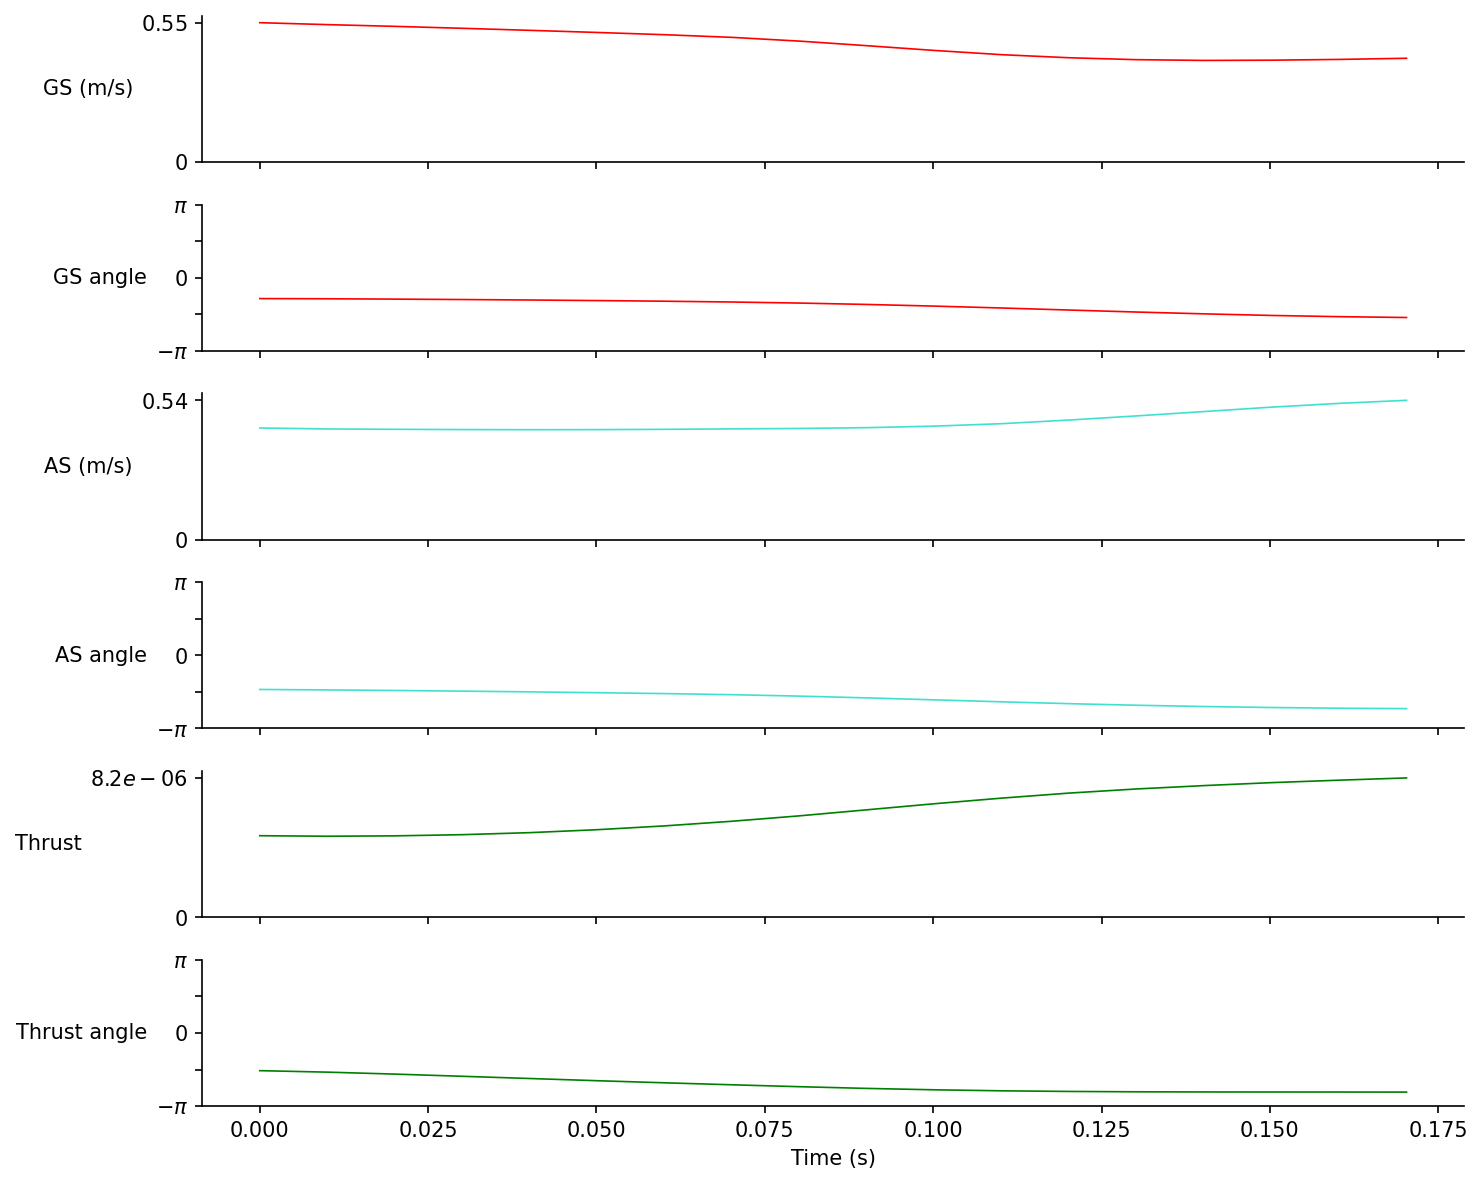

In [10]:
import os, sys
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('../utils'))
import pandas as pd
from utils import plot_fly_inputs_stacked

augmented_all_fly_data = pd.read_csv('../trainingdata/02_augmented/all_wind_heading_and_trajectories_augmented.csv')
panel_b_trajec = augmented_all_fly_data.loc[augmented_all_fly_data["trajec_objid"] == "20130327_193200_13850"]

fig, axes = plt.subplots(6, 1, figsize=(10, 8), dpi=150, sharex=True)
plot_fly_inputs_stacked(panel_b_trajec, axes=axes)
fig.tight_layout()

os.makedirs('../figures', exist_ok=True)
fig.savefig('../figures/kinematic_variables_over_trajectory.svg', format='svg', bbox_inches='tight')
plt.show()

### `04_trainingdata`

Load the corrected, filtered trajectories, add the `heading_angle_x`/`heading_angle_y` output columns (the unit-vector form of the target heading), and write the result to `04_trainingdata/`. The `heading_confidence` column from the correction is kept, so low-confidence frames can be left out of a training set. 

In [11]:
import os
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np

final_all_fly_data = pd.read_csv('../trainingdata/03_corrected/all_wind_heading_and_trajectories_augmented_corrected.csv')
final_all_fly_data['heading_angle_x'] = np.cos(final_all_fly_data['heading_angle'])
final_all_fly_data['heading_angle_y'] = np.sin(final_all_fly_data['heading_angle'])
os.makedirs('../trainingdata/04_trainingdata', exist_ok=True)
final_all_fly_data.to_csv('../trainingdata/04_trainingdata/all_wind_heading_and_trajectories_augmented_corrected_filtered_headx_heady.csv', index=False)